# 05 · Evaluación comparativa

Objetivo: comparar SVM vs. Random Forest y elegir el modelo final.

- Matriz de confusión por modelo
- Precision, recall, F1 y accuracy
- Curvas ROC/PR cuando aplique
- Conclusión y recomendación

In [1]:

import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    hamming_loss,
    classification_report
)

carpeta_datos = Path("../data/procesado")
carpeta_modelos = Path("../models")
carpeta_modelos.mkdir(parents=True, exist_ok=True)

X_train = np.load(carpeta_datos / "X_train.npy")
X_test = np.load(carpeta_datos / "X_test.npy")
y_train = np.load(carpeta_datos / "y_train.npy")
y_test = np.load(carpeta_datos / "y_test.npy")

columnas_sabores = [
    "dulce", "salado", "amargo", "acido", "umami"
]

modelo_lr = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", OneVsRestClassifier(
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ),
        n_jobs=-1
    ))
])

print("Entrenando regresión logística...")
modelo_lr.fit(X_train, y_train)

joblib.dump(
    modelo_lr,
    carpeta_modelos / "regresion_logistica_multietiqueta.joblib"
)

print("Modelo entrenado y guardado.")


Entrenando regresión logística...
Modelo entrenado y guardado.


In [2]:

y_pred_lr = modelo_lr.predict(X_test)

metricas_lr = {
    "F1 macro": f1_score(
        y_test, y_pred_lr, average="macro", zero_division=0
    ),
    "F1 micro": f1_score(
        y_test, y_pred_lr, average="micro", zero_division=0
    ),
    "Precision macro": precision_score(
        y_test, y_pred_lr, average="macro", zero_division=0
    ),
    "Recall macro": recall_score(
        y_test, y_pred_lr, average="macro", zero_division=0
    ),
    "Hamming loss": hamming_loss(y_test, y_pred_lr)
}

print("MÉTRICAS DE REGRESIÓN LOGÍSTICA")
for nombre, valor in metricas_lr.items():
    print(f"{nombre}: {valor:.4f}")

print("\nREPORTE POR SABOR")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=columnas_sabores,
    zero_division=0
))

np.save(carpeta_datos / "y_pred_lr.npy", y_pred_lr)

pd.DataFrame([
    {"modelo": "Regresión logística", "metrica": nombre, "valor": valor}
    for nombre, valor in metricas_lr.items()
]).to_csv(
    carpeta_datos / "metricas_lr.csv",
    index=False
)

print("Predicciones y métricas guardadas.")


MÉTRICAS DE REGRESIÓN LOGÍSTICA
F1 macro: 0.4769
F1 micro: 0.6011
Precision macro: 0.4673
Recall macro: 0.4900
Hamming loss: 0.3506

REPORTE POR SABOR
              precision    recall  f1-score   support

       dulce       0.44      0.44      0.44       571
      salado       0.78      0.77      0.77      1127
      amargo       0.09      0.13      0.11        67
       acido       0.37      0.45      0.40       509
       umami       0.66      0.66      0.66       927

   micro avg       0.59      0.61      0.60      3201
   macro avg       0.47      0.49      0.48      3201
weighted avg       0.60      0.61      0.61      3201
 samples avg       0.58      0.61      0.56      3201

Predicciones y métricas guardadas.


In [3]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

carpeta_datos = Path("../data/procesado")

# Cargar métricas de los tres modelos
metricas_svm = pd.read_csv(carpeta_datos / "metricas_svm.csv")
metricas_rf = pd.read_csv(carpeta_datos / "metricas_rf.csv")
metricas_lr = pd.read_csv(carpeta_datos / "metricas_lr.csv")

# Unir los resultados
comparacion = pd.concat(
    [metricas_svm, metricas_rf, metricas_lr],
    ignore_index=True
)

# Tabla con una fila por modelo
tabla_comparativa = comparacion.pivot(
    index="modelo",
    columns="metrica",
    values="valor"
)

columnas_orden = [
    "F1 macro",
    "F1 micro",
    "Precision macro",
    "Recall macro",
    "Hamming loss"
]

tabla_comparativa = tabla_comparativa[columnas_orden]

display(tabla_comparativa.round(4))

# Guardar la tabla
tabla_comparativa.to_csv(
    carpeta_datos / "comparacion_modelos.csv"
)


metrica,F1 macro,F1 micro,Precision macro,Recall macro,Hamming loss
modelo,,,,,
Random Forest,0.3359,0.6679,0.6068,0.4045,0.2766
Regresión logística,0.4769,0.6011,0.4673,0.4900,0.3506
SVM,0.5008,0.6800,0.4941,0.5088,0.2777


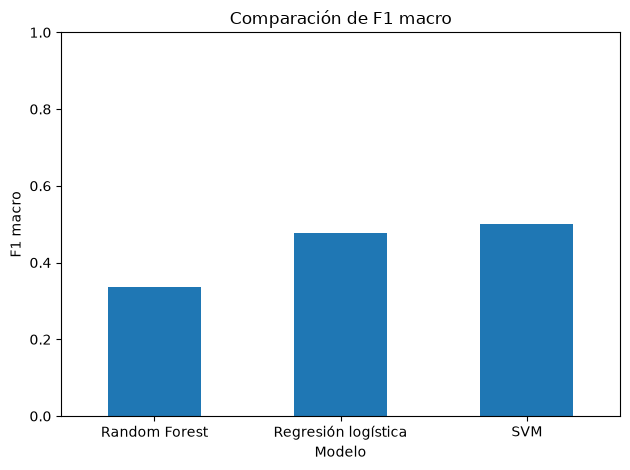

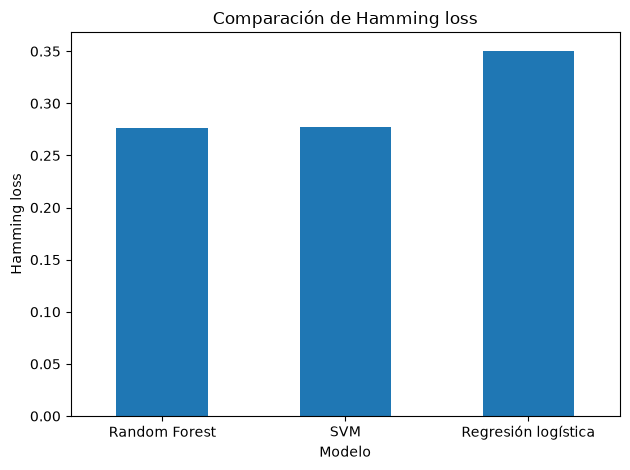

In [4]:

# Comparar F1 macro: mayor es mejor
tabla_comparativa["F1 macro"].sort_values().plot(
    kind="bar",
    title="Comparación de F1 macro",
    ylabel="F1 macro",
    xlabel="Modelo",
    ylim=(0, 1),
    rot=0
)

plt.tight_layout()
plt.show()

# Comparar Hamming loss: menor es mejor
tabla_comparativa["Hamming loss"].sort_values().plot(
    kind="bar",
    title="Comparación de Hamming loss",
    ylabel="Hamming loss",
    xlabel="Modelo",
    rot=0
)

plt.tight_layout()
plt.show()


Modelo,Random Forest,Regresión logística,SVM
Sabor,,,
acido,0.0039,0.4039,0.4060
amargo,0.0000,0.1084,0.0000
dulce,0.0440,0.4402,0.5144
salado,0.8626,0.7735,0.8436
umami,0.7689,0.6584,0.7399


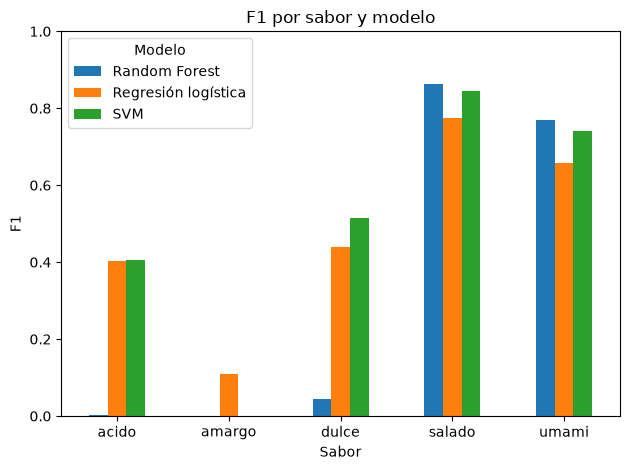

In [5]:

import numpy as np
from sklearn.metrics import f1_score

columnas_sabores = [
    "dulce", "salado", "amargo", "acido", "umami"
]

# Cargar etiquetas reales y predicciones guardadas
y_test = np.load(carpeta_datos / "y_test.npy")

predicciones = {
    "SVM": np.load(carpeta_datos / "y_pred_svm.npy"),
    "Random Forest": np.load(carpeta_datos / "y_pred_rf.npy"),
    "Regresión logística": np.load(carpeta_datos / "y_pred_lr.npy")
}

resultados_sabores = []

for nombre_modelo, predicciones_modelo in predicciones.items():
    f1_por_sabor = f1_score(
        y_test,
        predicciones_modelo,
        average=None,
        zero_division=0
    )

    for sabor, puntuacion in zip(columnas_sabores, f1_por_sabor):
        resultados_sabores.append({
            "Modelo": nombre_modelo,
            "Sabor": sabor,
            "F1": puntuacion
        })

df_sabores = pd.DataFrame(resultados_sabores)

display(
    df_sabores.pivot(
        index="Sabor",
        columns="Modelo",
        values="F1"
    ).round(4)
)

df_sabores.to_csv(
    carpeta_datos / "f1_por_sabor.csv",
    index=False
)

df_sabores.pivot(
    index="Sabor",
    columns="Modelo",
    values="F1"
).plot(
    kind="bar",
    title="F1 por sabor y modelo",
    ylabel="F1",
    xlabel="Sabor",
    ylim=(0, 1),
    rot=0
)

plt.tight_layout()
plt.show()
